Fouten in neural network-5 opgelost.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [2]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [3]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [4]:
def grad(act, wt, bs, ins, outs):
    
    gr_act = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    ind = []   
    for i in range(L):
        ind.append(list(range(len(act[i]))))


    for i in range(L-1): 
        for j in range(len(act[i])):
            gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * (wt[-1][k][j] if i == L-2 
                else sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * (wt[-2][l][j] if i == L-3 
                else sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * (wt[-3][m][j] if i == L-4 
                else sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * (wt[-4][n][j] if i == L-5 
                else sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * (wt[-5][o][j] if i == L-6
                else sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * (wt[-6][p][j] if i == L-7
                else sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * (wt[-7][q][j] if i == L-8
                else sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * (wt[-8][r][j] if i == L-9
                else sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * (wt[-9][s][j] if i == L-10 
                else sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    for t in ind[-10]])) for s in ind[-9]])) for r in ind[-8]])) for q in ind[-7]])) for p in ind[-6]])) 
                    for o in ind[-5]])) for n in ind[-4]])) for m in ind[-3]])) for l in ind[-2]])) for k in ind[-1]])
            
    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                gr_bs[i][j] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])
        elif i == 0:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j])
        else:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])

    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]
        elif i == 0:
            for j in range(len(bs[i])):
                for k in range(len(ins)):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j]) * ins[k]
        else:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]         

    
    return gr_act, gr_wt, gr_bs

In [88]:
def neural_network(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations, fraction):

    biases = []
    for i in range(len(nodes_hidden_layers)):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs[0])))
    
    weights = []
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs[0]))))
    
    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs[0]), nodes_hidden_layers[-1])))

    cost = []

    number = round(fraction*len(inputs))
    
    for k in range(iterations):

        if number == len(outputs):
            inputs_part = inputs
            outputs_part = outputs

        else:
            end = int((number*(k+1)/len(outputs) - number*(k+1)//len(outputs))*len(outputs)) - 1
            start = end - (number-1)

            if start < 0:
                start = start + len(outputs)
            if end < 0:
                end = end + len(outputs)
    
            if start > end:
                inputs_part = np.vstack((inputs[start:], inputs[:end+1]))
                outputs_part = np.vstack((outputs[start:], outputs[:end+1]))
            else:
                inputs_part = inputs[start:end+1]
                outputs_part = outputs[start:end+1]

        iter_cost = 0

        gr_b = [0*bias for bias in biases]
        gr_w = [0*weight for weight in weights]
        gr_act = gr_b
        
        for j in range(inputs_part.shape[0]):        
            
            activations = det_activations(inputs_part[j], weights, biases)
            iter_cost +=  (1/inputs_part.shape[0]) * sum([(activations[-1].tolist()[i] - outputs_part[j][i])**2 
                                                          for i in range(len(outputs_part[j]))])
        
            gr_act_p, gr_w_p, gr_b_p = grad(activations, weights, biases, inputs_part[j], outputs_part[j])

            gr_b = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_b, gr_b_p)]
            gr_w = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_w, gr_w_p)]
            gr_act = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_act, gr_act_p)]
            
        weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
        biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

        cost.append(iter_cost)

    return activations, weights, biases, cost

In [6]:
inputs = np.random.rand(4,20)
outputs = [[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]]

In [80]:
outputs[-2:-1]

[[0.1, 0.9, 0.13, 0.98, 0.4, 0.5]]

In [84]:
number = 3

k = 2

if number == len(outputs):
    inputs_part = inputs
    outputs_part = outputs

else:
    end = int((number*(k+1)/len(outputs) - number*(k+1)//len(outputs))*len(outputs)) - 1
    start = end - (number-1)

    if start < 0:
        start = start + len(outputs)
    if end < 0:
        end = end + len(outputs)
    
    if start > end:
        inputs_part = np.vstack((inputs[start:], inputs[:end+1]))
        outputs_part = np.vstack((outputs[start:], outputs[:end+1]))
    else:
        inputs_part = inputs[start:end+1]
        outputs_part = outputs[start:end+1]

In [85]:
inputs

array([[7.36181773e-01, 8.12271783e-01, 8.03102482e-01, 1.24336890e-04,
        1.19808852e-01, 8.12923929e-01, 6.71871498e-01, 8.42747418e-01,
        2.63526045e-01, 7.02592954e-01, 7.69782093e-01, 9.23447896e-01,
        3.57651915e-01, 1.69623355e-01, 4.70654670e-02, 8.73919618e-01,
        9.79423680e-01, 7.56398454e-01, 2.39869669e-01, 3.76689949e-01],
       [4.64200992e-01, 3.08506325e-01, 8.71416900e-01, 6.44670344e-01,
        8.96189646e-01, 3.24547355e-01, 7.74917270e-01, 7.97534778e-02,
        9.10642447e-01, 5.07596536e-01, 9.65933652e-01, 1.86671793e-01,
        5.09038226e-01, 5.45830027e-01, 6.54918093e-01, 8.91643492e-02,
        5.79940631e-02, 4.04113454e-01, 3.49135115e-01, 4.52285740e-01],
       [7.13888253e-01, 3.54994385e-01, 8.18567381e-01, 7.59998961e-01,
        7.06031948e-01, 7.12304118e-02, 2.76271889e-02, 1.75527154e-01,
        3.92849658e-01, 9.09423085e-01, 6.13617299e-01, 6.19025102e-01,
        8.40931868e-01, 7.68566926e-01, 4.80311147e-01, 9.6186

In [86]:
inputs_part

array([[7.13888253e-01, 3.54994385e-01, 8.18567381e-01, 7.59998961e-01,
        7.06031948e-01, 7.12304118e-02, 2.76271889e-02, 1.75527154e-01,
        3.92849658e-01, 9.09423085e-01, 6.13617299e-01, 6.19025102e-01,
        8.40931868e-01, 7.68566926e-01, 4.80311147e-01, 9.61867089e-01,
        9.31151771e-01, 3.75028296e-02, 8.65066761e-01, 8.49340482e-01],
       [7.70931096e-01, 9.00849905e-01, 1.80019689e-01, 9.01252981e-01,
        6.11783036e-01, 2.76540032e-01, 8.04314272e-01, 4.78419766e-01,
        2.91122981e-01, 6.42146617e-01, 1.29557045e-01, 6.04867478e-01,
        9.13122910e-01, 6.96098879e-01, 3.10922343e-01, 9.31146066e-01,
        9.31744064e-01, 6.21500345e-01, 8.40637529e-02, 3.60656952e-01],
       [7.36181773e-01, 8.12271783e-01, 8.03102482e-01, 1.24336890e-04,
        1.19808852e-01, 8.12923929e-01, 6.71871498e-01, 8.42747418e-01,
        2.63526045e-01, 7.02592954e-01, 7.69782093e-01, 9.23447896e-01,
        3.57651915e-01, 1.69623355e-01, 4.70654670e-02, 8.7391

In [87]:
outputs_part

array([[0.1  , 0.9  , 0.13 , 0.98 , 0.4  , 0.5  ],
       [0.2  , 0.22 , 0.222, 0.4  , 0.05 , 0.6  ],
       [1.   , 0.3  , 0.2  , 0.5  , 0.6  , 0.8  ]])

Time taken for 1 layer of 5 nodes: 0.971696138381958 seconds
Time taken for 2 layes of 5 nodes: 2.012773036956787 seconds
Time taken for 3 layers of 5 nodes: 6.861202001571655 seconds
Time taken for 4 layers of 5 nodes: 29.989802837371826 seconds


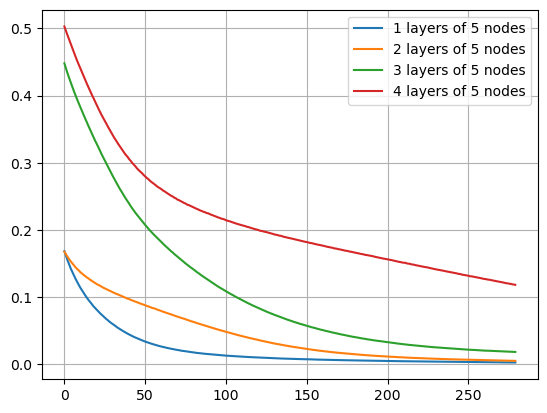

In [89]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 5 nodes: 0.48505425453186035 seconds
Time taken for 2 layes of 5 nodes: 1.024327039718628 seconds
Time taken for 3 layers of 5 nodes: 3.4616611003875732 seconds
Time taken for 4 layers of 5 nodes: 15.427629232406616 seconds


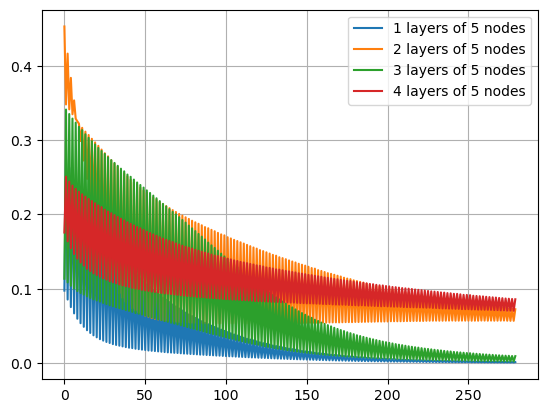

In [90]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 8 nodes: 1.082252025604248 seconds
Time taken for 2 layes of 8 nodes: 2.9296820163726807 seconds
Time taken for 3 layers of 8 nodes: 15.706692695617676 seconds
Time taken for 4 layers of 8 nodes: 124.78241491317749 seconds


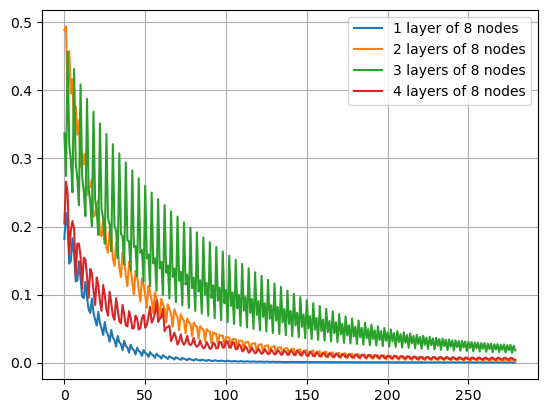

In [91]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 1 layer of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 2 layes of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [8, 8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 3 layers of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [8, 8, 8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 4 layers of 8 nodes:", end - start, "seconds")

#laatste 5: max_bias, max_weight, learning_rate, iterations, fraction

plt.plot(cost_a[20:], label="1 layer of 8 nodes");
plt.plot(cost_b[20:], label="2 layers of 8 nodes");
plt.plot(cost_c[20:], label="3 layers of 8 nodes");
plt.plot(cost_d[20:], label="4 layers of 8 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 5 nodes: 5.813298940658569 seconds
Time taken for 2 layes of 5 nodes: 12.648329257965088 seconds
Time taken for 3 layers of 5 nodes: 48.65955090522766 seconds


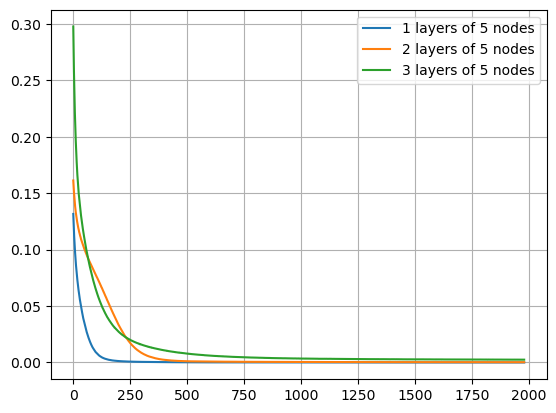

In [92]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.grid();
plt.legend();

In [93]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [94]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [137]:
train_data['label'].head()

0    5
1    0
2    4
3    1
4    9
Name: label, dtype: int64

Time taken for 2 layers of 16 nodes: 896.7442202568054 seconds


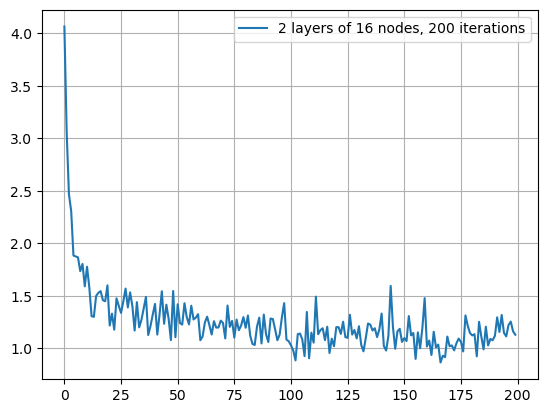

In [97]:
start = time.time()  
activations, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16, 16], 1, 1, 1, 200, 0.001) 
end = time.time()

print("Time taken for 2 layers of 16 nodes:", end - start, "seconds")

plt.plot(cost_2, label="2 layers of 16 nodes, 200 iterations");
plt.grid();
plt.legend();

In [98]:
y_test

0       7
1       2
2       1
3       0
4       4
       ..
9995    2
9996    3
9997    4
9998    5
9999    6
Name: label, Length: 10000, dtype: int64

In [99]:
def predict(inputs, weights, biases, labels):

    outputs = []

    for i in range(len(inputs)):

        activations = det_activations(inputs[i], weights, biases)
        outputs.append(labels[np.argmax(activations[-1])])

    return outputs

In [100]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [102]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

In [103]:
y_predict_2 = predict(X_test, weights_2, biases_2, labels)
accuracy_score(y_test,y_predict_2)

0.3144

In [104]:
y_test[:10]

0    7
1    2
2    1
3    0
4    4
5    1
6    4
7    9
8    5
9    9
Name: label, dtype: int64

In [105]:
y_predict_2[:10]

[7, 0, 2, 7, 4, 1, 0, 6, 4, 4]